# W10A · 실습 A · FM 복습과 Keras MF

**딥러닝응용I(추천시스템) · 동덕여자대학교 데이터사이언스전공 · 유원상 교수 · 2026-2 · 2026-11-03**

FM의 손계산을 확인하고 원핫 조회·내적·편향을 같은 고정 가중치의 Keras 모형으로 재현합니다. 이어 독립 데이터 준비부터 작은 실제 MF 학습까지 실행합니다.

CPU 런타임에서 Drive에 사본을 저장하고 첫 셀부터 실행하세요. 설치 후 재시작 안내가 나오면 런타임을 재시작하고 처음부터 실행합니다. 개인 파일 업로드·API키·유료GPU가 필요하지 않습니다. `None`은 자신의 답을 적는 빈칸이며 기본 수업 변수와 분리되어 이후 실행을 막지 않습니다. 먼저 예상하고 실행 후 이유를 쓰세요.

아래 설치는 검토한 수업 ref를 사용합니다. 실제 Colab·공개 ref 검증은 배포 증거와 별도로 확인합니다.


In [ ]:
import os,sys,subprocess
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'
os.environ['TF_ENABLE_ONEDNN_OPTS']='0'
os.environ['GRADIO_ANALYTICS_ENABLED']='False'
IN_COLAB = 'google.colab' in sys.modules
COURSE_VERSION = '2026-fall-w10a'
if IN_COLAB:
    subprocess.run([sys.executable,'-m','pip','install','-q',
        f'luna-recommender-course[apps,neural] @ git+https://github.com/lunalab-ai/recommender.git@{COURSE_VERSION}',
        'gradio==6.26.0'],check=True)
    for name,wanted in [('tensorflow','2.21.0'),('keras','3.15.1')]:
        if name in sys.modules and getattr(sys.modules[name],'__version__',None)!=wanted:
            raise RuntimeError('설치가 갱신되었습니다. 런타임을 재시작하고 첫 셀부터 다시 실행하세요.')
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from IPython.display import display,Markdown
from luna_recsys.datasets import prepare_movielens
from luna_recsys.neural_recommenders import (fixed_forward,prepare_neural_data,
    build_mf,build_mlp,rating_metrics,predict_ratings,fit_neural)
from luna_recsys.model_comparison import definition_link
print('Python',sys.version.split()[0],'NumPy',np.__version__,'TensorFlow',tf.__version__,'Keras',keras.__version__)
print('수업 ref',COURSE_VERSION,'CPU로 실행 가능')


## 재사용 API를 먼저 읽기

`prepare_movielens(mode='synthetic')`는 독자 합성80명·18편·960평점을 메모리에 준비합니다. `mode='real'`은 공식 MovieLens를 다운로드/캐시하며 실패를 합성으로 숨기지 않습니다. `prepare_neural_data`는 키 결합·관측70/15/15분할 후 훈련에서만 ID 사전·평균·나이 스케일을 만듭니다.

`fixed_forward`는 주어진 합성 모수의 중간값 사전입니다. `build_mf/build_mlp`는 학습 전 Keras 모형을 만듭니다. 표 행 수에는 예약0이 포함됩니다. 모형 생성/학습은 Python·NumPy·TF의 전역 seed를 설정합니다. `fit_neural`은 실제 학습과 검증epoch선택 후 시험 평가를 수행합니다. `predict_ratings`는 평균을 복원한1차원 예측과 warm-ID mask를 반환합니다. `rating_metrics`는 두1차원 배열의 MSE/RMSE를 검사합니다. 다운로드 외에는 원자료를 파일로 복제하지 않습니다.

각 함수의 자세한 입력·반환·기본값은 강의의 API 안내와 아래 실제 정의 위치에서 확인하세요.


In [ ]:
functions=[prepare_movielens,prepare_neural_data,fixed_forward,build_mf,build_mlp,
           predict_ratings,rating_metrics,fit_neural]
display(Markdown('\n'.join(f'- [{f.__name__}]({definition_link(f,COURSE_VERSION)})' for f in functions)))


## FM의 중간값

입력x는 사용자·영화·맥락이고 정답y는 별도입니다. `toy_parameters`는 새 합성w/V를 반환하며 `fm_score`는 편향·선형항·상호작용·예측 사전, `pair_contributions`는 활성 쌍 목록을 반환합니다. `fm_score_naive`는 쌍을 직접 세는 독립 검산 함수입니다.

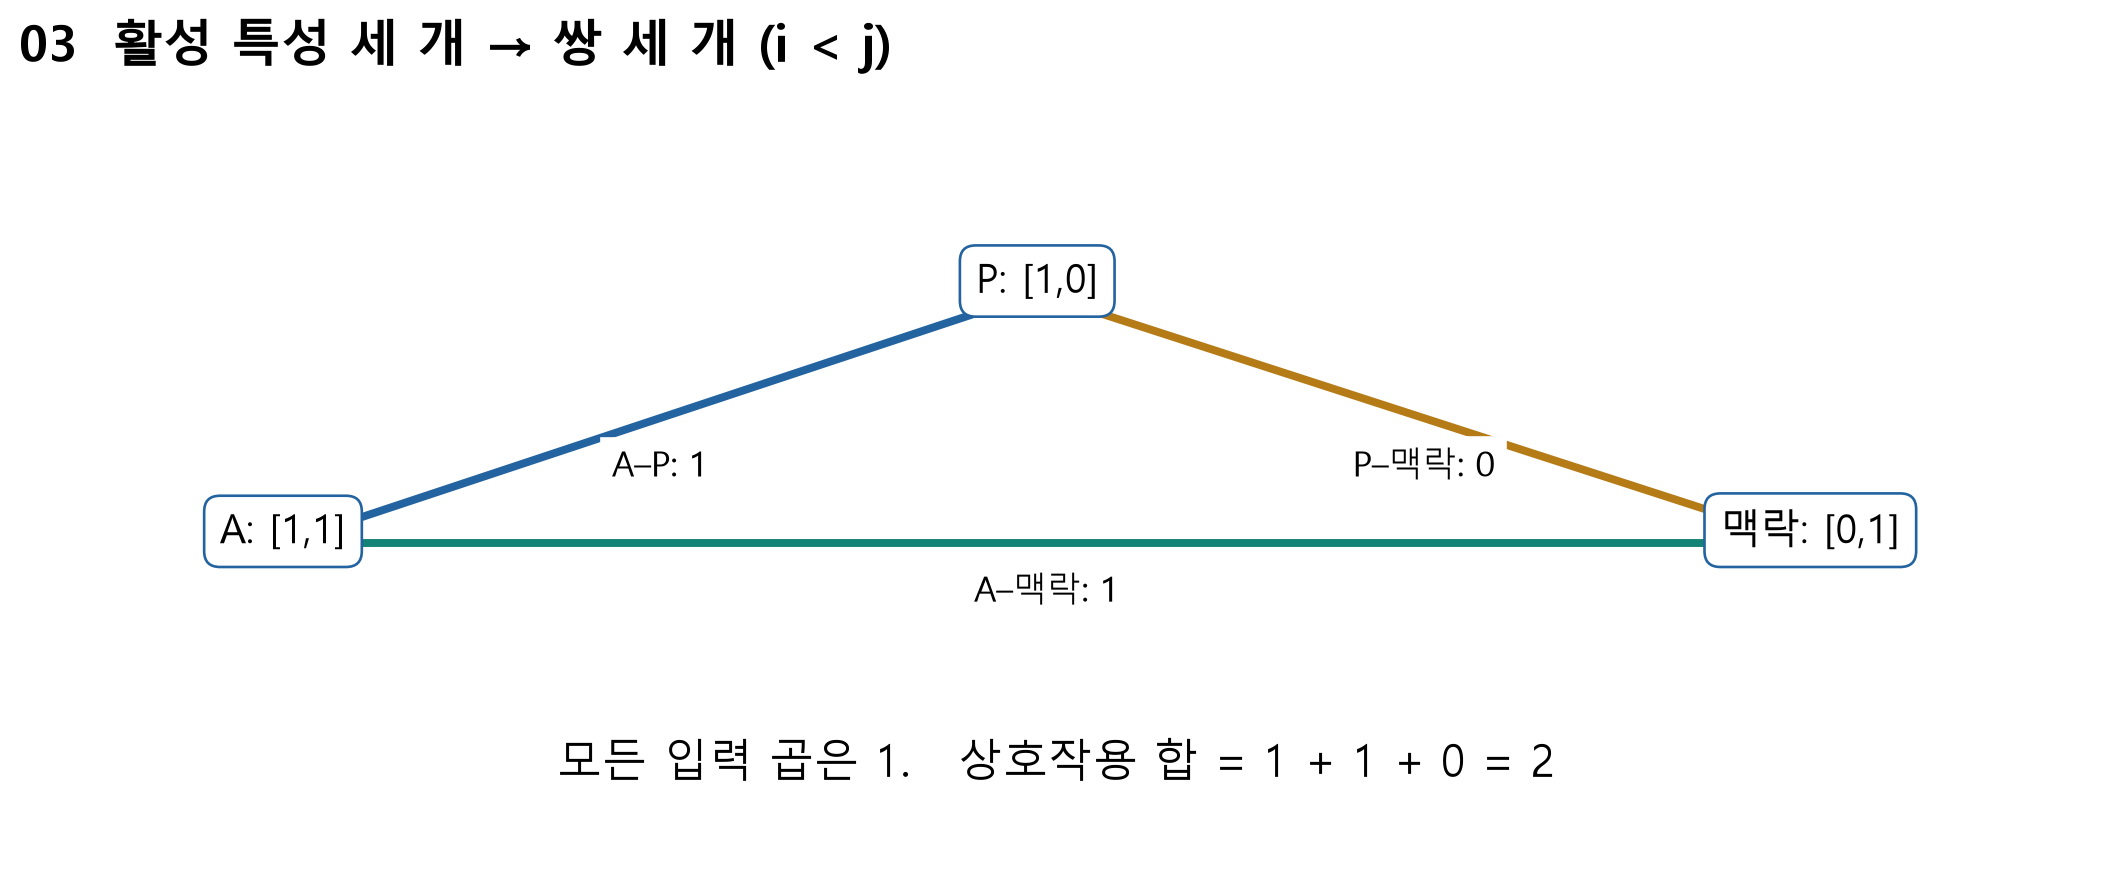


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w09b/course/notion/assets/w09b/03-active-pairs.png)


In [ ]:
from luna_recsys.fm_core import toy_parameters,encode_observation,fm_score,fm_score_naive,pair_contributions
p=toy_parameters(); x=encode_observation('A','P',1)
fm=fm_score(x,p['w'],p['V'],p['bias'])
display(pd.DataFrame(pair_contributions(x,p['V'])))
print({key:fm[key] for key in ['bias','linear','interaction','prediction']})


## L01 · 입력과 예측

워크북 L01을 종이에서 풀고 맥락2를 실행 전에 예상하세요. 입력·정답·기여 합을 분리합니다. 힌트: 활성 쌍의 입력 곱을 포함합니다. 자가점검: 직접 합과 효율식이 같은가요?


In [ ]:
my_x=None
my_prediction_context2=None
print('내 답:',my_x,my_prediction_context2)


## L02 · 다른 FM으로 전이

워크북 L02의 x=[1,1,2],w=[.2,−.1,.4],V행=[1,0],[0,1],[1,−1],bias=.5를 계산합니다. 힌트: 입력2의 자기항 제곱. 자가점검: 두 식의 차이가0인가요?


In [ ]:
my_other_fm=None
print('내 예측:',my_other_fm)


## 같은 모수를 Keras MF에 넣기

이 작은 표에서는 A/B와 P/Q를 각각0/1로 직접 정의합니다. 실제 데이터 준비 함수의 예약0 규약과 별개인 고정 모수 예입니다. 모델 출력은 중심화 점수이며 주어진 평균1을 외부에서 더합니다. 임베딩 표를 학습으로 얻은 것처럼 설명하지 않습니다.


In [ ]:
frozen=build_mf(2,2,k=2,reg=0)
for name,weights in [('user_embedding',[[1,1],[.3,-.2]]),('item_embedding',[[1,0],[-.1,.4]]),
                     ('user_bias',[[.5],[.2]]),('item_bias',[[-.5],[-.1]])]:
    frozen.get_layer(name).set_weights([np.array(weights,dtype='float32')])
centered=np.asarray(frozen({'user_id':np.array([[0]],dtype='int32'),
                            'movie_id':np.array([[0]],dtype='int32')},training=False)).reshape(-1)
print('중심화 점수',centered,'평균1 복원',centered+1)
display(pd.DataFrame([{'layer':layer.name,'output_shape':str(layer.output.shape)} for layer in frozen.layers]))


## L03 · 원핫 조회와 예측

워크북 L03의 표/원핫/q로 벡터와 내적을 구하고 평균·편향을 더하세요. 힌트: 선택 행 하나만 사용합니다. 자가점검: 자동 clipping을 가정했나요?


In [ ]:
my_lookup=None
my_mf_prediction=None
print(my_lookup,my_mf_prediction)


## L04 · 배열과 모수

B4/K3의 shape와 표행수M3/N4의 MF 모수 수, 기본 MLP 연결을 Dense2로 보낼 때 모수 수를 적으세요. 힌트: Dense 편향2개. 자가점검: B가 모수 수를 바꾸나요?


In [ ]:
my_shapes=None
my_parameter_counts=None
print(my_shapes,my_parameter_counts)


## 실제 데이터 준비·분할·MF 학습

`DATA_MODE` 기본값은synthetic입니다. `real`로 바꾸면 공식 다운로드/캐시를 사용합니다. `max_rows=5000`은 실제 데이터의 명시적인 작은 부분집합이며 전체100K 재현 결과가 아닙니다. 관측의 row_id 중복, 평균의 적합 범위를 먼저 확인합니다. 학습은 최대4에포크로 짧게 실행합니다.


In [ ]:
DATA_MODE='synthetic'
prepared=prepare_movielens(cache_dir='data/local/w10a',mode=DATA_MODE)
data=prepare_neural_data(prepared,max_rows=5000 if DATA_MODE=='real' else None)
print(prepared.description)
print('분할',{name:len(frame) for name,frame in data.frames.items()},'표 행 수',data.dimensions,'훈련 평균',data.mean)
result=fit_neural(data,'mf',epochs=4)
display(result['history'])
display(pd.DataFrame(result['metrics']).T)
print('선택epoch',result['best_epoch'],'설정',result['setting'])


## L07 · 방송 오류를 고치기

워크북 L07의 정답[1,3]과 예측[[1],[2]]을 같은1차원 shape로 맞춰 MSE를 구하세요. 힌트: reshape(-1). 자가점검: 차이가 관측 수만큼인가요?


In [ ]:
my_mse=None
print('내 MSE:',my_mse)


## 점검 퀴즈

1. 정답평점을 입력에 넣으면 왜 문제가 되나요?
2. FM의K와 활성 쌍 수는 어떻게 다른가요?
3. 정수ID로 임베딩의 무엇을 선택하나요?
4. 모델 출력에 훈련 평균을 더하는 이유는 무엇인가요?
5. `(B,1)` 예측과 `(B,)` 정답을 바로 빼면 무엇이 생길 수 있나요?

핵심 정리: 입력·정답 분리, 조회·내적·편향, 배치 축, 훈련 통계의 범위가 우선입니다.

참고: 주교재5.1–5.4/6.1–6.2, 강의 API 안내, [Keras Embedding](https://keras.io/api/layers/core_layers/embedding/).


In [ ]:
np.testing.assert_allclose(centered,[1.],atol=1e-6)
assert np.isclose(fm['prediction'],fm_score_naive(x,p['w'],p['V'],p['bias']))
ids=[set(frame.row_id) for frame in data.frames.values()]
assert not (ids[0]&ids[1] or ids[0]&ids[2] or ids[1]&ids[2])
assert np.isclose(data.mean,data.frames['train'].rating.mean())
assert np.isfinite(result['history'].to_numpy()).all()
assert result['predictions']['test'].ndim==1
assert result['best_epoch'] in result['history'].epoch.to_list()
print('W10A_MF_RUNTIME_PASS',prepared.mode)
